In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

url = "https://raw.githubusercontent.com/sugatagh/E-commerce-Text-Classification/main/Dataset/ecommerceDataset.csv"

df = pd.read_csv(
    url,
    header=None,
    names=["label", "description"]
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (50425, 2)


,label,description
0,Household,Paper Plane Design Framed Wall Hanging Motivat...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ..."
2,Household,SAF 'UV Textured Modern Art Print Framed' Pain...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 1..."
4,Household,Incredible Gifts India Wooden Happy Birthday U...


In [2]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50425 entries, 0 to 50424
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   label        50425 non-null  object
 1   description  50424 non-null  object
dtypes: object(2)
memory usage: 788.0+ KB

Missing values:
label          0
description    1
dtype: int64

Duplicate records: 22622

Class distribution:
label
Household                 19313
Books                     11820
Electronics               10621
Clothing & Accessories     8671
Name: count, dtype: int64


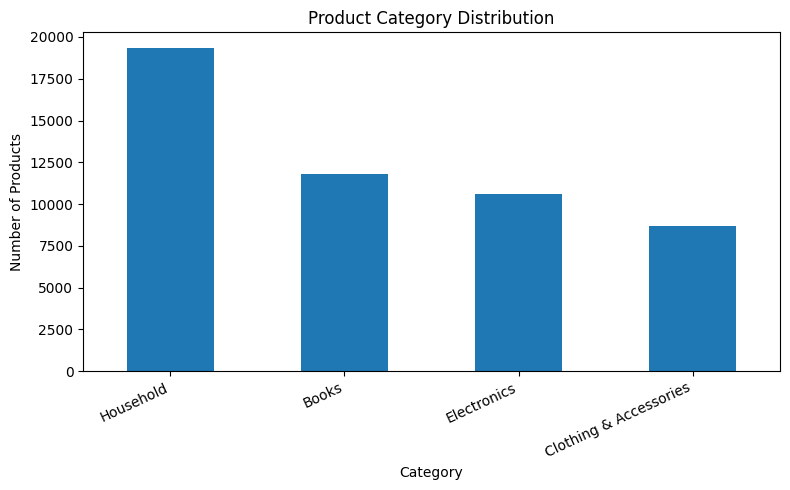

In [3]:
df["label"].value_counts().plot(kind="bar", figsize=(8, 5))

plt.title("Product Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [4]:
df = df.dropna(subset=["label", "description"]).copy()

df["label"] = df["label"].str.strip()
df["description"] = df["description"].str.strip()

df = df[
    (df["label"] != "") &
    (df["description"] != "")
]

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("\nClass distribution after cleaning:")
print(df["label"].value_counts())

Dataset shape after cleaning: (27781, 2)

Class distribution after cleaning:
label
Household                 10564
Books                      6235
Clothing & Accessories     5674
Electronics                5308
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X = df["description"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 22224
Testing samples: 5557


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

Training data shape: (22224, 10000)
Testing data shape: (5557, 10000)
Number of features: 10000


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.29 %

Classification Report:
                        precision    recall  f1-score   support

                 Books       0.96      0.93      0.95      1247
Clothing & Accessories       0.98      0.97      0.98      1135
           Electronics       0.95      0.93      0.94      1062
             Household       0.94      0.96      0.95      2113

              accuracy                           0.95      5557
             macro avg       0.96      0.95      0.95      5557
          weighted avg       0.95      0.95      0.95      5557



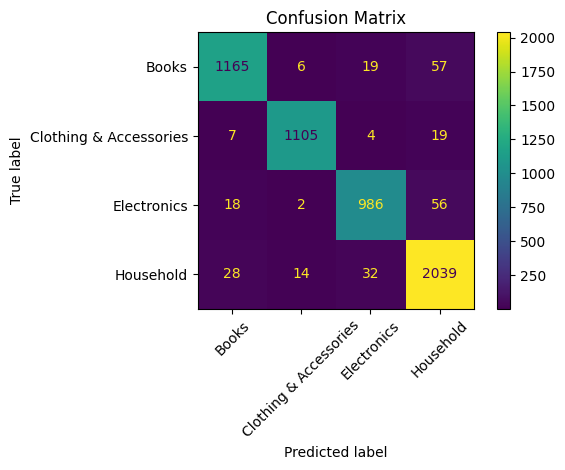

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()